<a href="https://colab.research.google.com/github/mariettarosemathew-ui/Assesment_SupervisedLearning_Marietta/blob/main/Assesment_SupervisedLearning_Marietta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Q1

In [169]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [170]:
df=pd.read_csv('/content/drive/MyDrive/DSA Class/Datasets/bank_marketing_assessment_dataset.csv')
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [171]:
df.shape

(600, 14)

In [172]:
df.columns

Index(['customer_age', 'job', 'marital_status', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact_type', 'contact_month',
       'campaign_contacts', 'previous_contacts', 'engagement_score',
       'annual_income_estimate', 'subscribed'],
      dtype='object')

In [173]:
df.dtypes

,0
customer_age,int64
job,object
marital_status,object
education,object
account_balance,float64
housing_loan,object
personal_loan,object
contact_type,object
contact_month,object
campaign_contacts,int64


In [174]:
df.isna().sum()

,0
customer_age,0
job,0
marital_status,0
education,15
account_balance,12
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [175]:
df.duplicated().sum()

np.int64(0)

In [176]:
df['subscribed'].value_counts()

,count
subscribed,
no,426
yes,174


In [177]:
percentage=df['subscribed'].value_counts(normalize=True)*100
print(percentage)

subscribed
no     71.0
yes    29.0
Name: proportion, dtype: float64


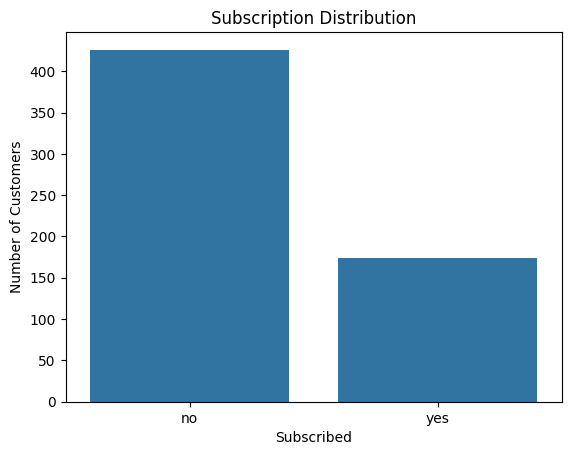

In [178]:
sns.countplot(data=df, x='subscribed')

plt.title('Subscription Distribution')
plt.xlabel('Subscribed')
plt.ylabel('Number of Customers')
plt.show()

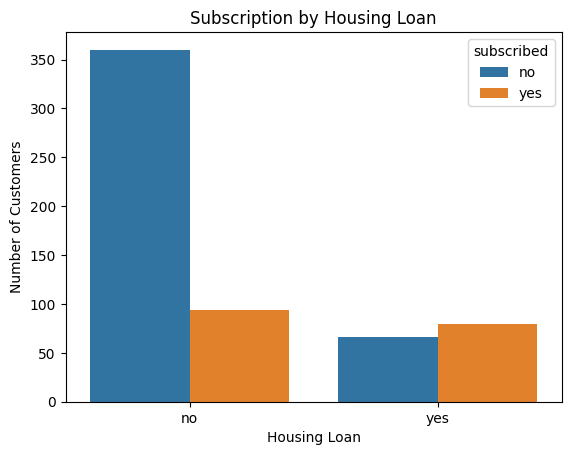

In [179]:
sns.countplot(data=df, x='housing_loan', hue='subscribed')

plt.title('Subscription by Housing Loan')
plt.xlabel('Housing Loan')
plt.ylabel('Number of Customers')
plt.show()

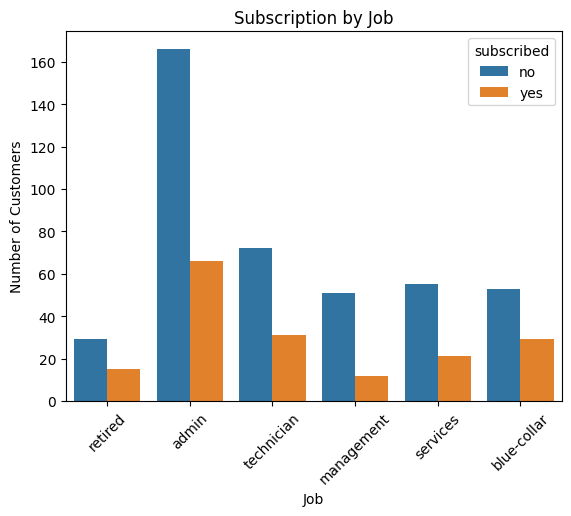

In [180]:
sns.countplot(data=df, x='job', hue='subscribed')

plt.title('Subscription by Job')
plt.xlabel('Job')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.show()

Most customers did not subscribe to the term deposit.It has more 'no' than 'yes'

Q2

In [181]:
y=df['subscribed']
x=df.drop(['subscribed'],axis=1)

In [182]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [183]:
numeric_columns = x_train.select_dtypes(include='number').columns.tolist()

categorical_columns = x_train.select_dtypes(include=['object', 'category']).columns.tolist()

In [184]:
numeric_medians = x_train[numeric_columns].median()

x_train[numeric_columns] = x_train[numeric_columns].fillna(numeric_medians)

x_test[numeric_columns] = x_test[numeric_columns].fillna(numeric_medians)

In [185]:
categorical_modes = x_train[categorical_columns].mode().iloc[0]

x_train[categorical_columns] = x_train[categorical_columns].fillna(categorical_modes)

x_test[categorical_columns] = x_test[categorical_columns].fillna(categorical_modes)

In [186]:
x_train = pd.get_dummies(x_train, columns=categorical_columns, dtype=int)

x_test = pd.get_dummies(x_test, columns=categorical_columns, dtype=int)

x_test = x_test.reindex(columns=x_train.columns, fill_value=0)

In [187]:
scaler = StandardScaler()

x_train[numeric_columns] = scaler.fit_transform(x_train[numeric_columns])

x_test[numeric_columns] = scaler.transform(x_test[numeric_columns])

In [188]:
print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

print("Training missing values:", x_train.isnull().sum().sum())
print("Testing missing values:", x_test.isnull().sum().sum())

Training shape: (480, 31)
Testing shape: (120, 31)
Training missing values: 0
Testing missing values: 0


Q3

In [189]:
from sklearn.linear_model import LogisticRegression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(x_train, y_train)

LogisticRegression(max_iter=1000)

In [190]:
from sklearn.ensemble import RandomForestClassifier
random_forest_model = RandomForestClassifier(n_estimators=100,random_state=42)
random_forest_model.fit(x_train, y_train)

RandomForestClassifier(random_state=42)

In [191]:
y_pred_logistic = logistic_model.predict(x_test)

In [192]:
y_pred_rf = random_forest_model.predict(x_test)

In [193]:
print("Logistic Regression predictions:")
print(y_pred_logistic)
print("Random Forest predictions:")
print(y_pred_rf)

Logistic Regression predictions:
['no' 'yes' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no'
 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'yes' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes'
 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no'
 'no' 'no' 'no' 'yes' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'yes' 'no'
 'yes' 'no' 'yes' 'no' 'yes' 'no' 'no' 'no' 'no']
Random Forest predictions:
['no' 'yes' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'yes' 'no'
 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'yes'
 'no' 'no' 'n

Q4

In [194]:
print(y_test.value_counts())

subscribed
no     85
yes    35
Name: count, dtype: int64


In [195]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [196]:
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(y_test, y_pred_logistic, pos_label='yes', zero_division=0)
logistic_recall = recall_score(y_test, y_pred_logistic, pos_label='yes', zero_division=0)
logistic_f1 = f1_score(y_test, y_pred_logistic, pos_label='yes', zero_division=0)

In [197]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, pos_label='yes', zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, pos_label='yes', zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, pos_label='yes', zero_division=0)

In [198]:
evaluation_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [logistic_accuracy, rf_accuracy],
    'Precision': [logistic_precision, rf_precision],
    'Recall': [logistic_recall, rf_recall],
    'F1 Score': [logistic_f1, rf_f1]})
evaluation_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.850000,0.869565,0.571429,0.689655
1,Random Forest,0.841667,0.807692,0.600000,0.688525


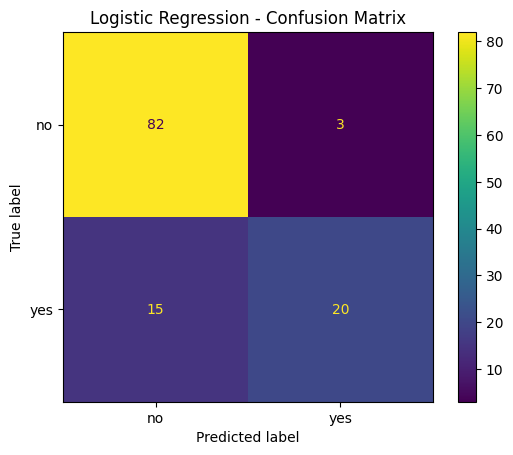

In [199]:
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=['no', 'yes'])
display_logistic = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=['no', 'yes'])
display_logistic.plot()
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

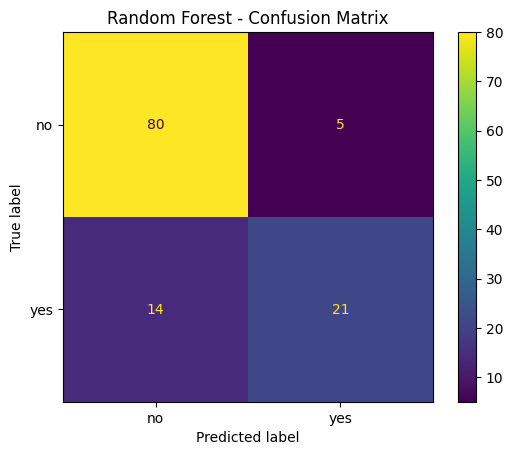

In [200]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=['no', 'yes'])
display_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['no', 'yes'])
display_rf.plot()
plt.title('Random Forest - Confusion Matrix')
plt.show()

In [201]:
evaluation_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.850000,0.869565,0.571429,0.689655
1,Random Forest,0.841667,0.807692,0.600000,0.688525


Logistic Regression has higher accuracy, precision and F1-score than Random Forest. However, Random Forest has higher recall (60%) compared to Logistic Regression (57.14%). Since the business wants to identify potential subscribers Random Forest is recommended. Both models performed similarly overall.

Q5

In [202]:
feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': random_forest_model.feature_importances_})
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False)
feature_importance

,Feature,Importance
0,customer_age,0.130188
5,annual_income_estimate,0.093062
21,personal_loan_yes,0.089840
20,personal_loan_no,0.088796
1,account_balance,0.078847
3,previous_contacts,0.076164
4,engagement_score,0.059827
2,campaign_contacts,0.050340
19,housing_loan_yes,0.037020
18,housing_loan_no,0.036216


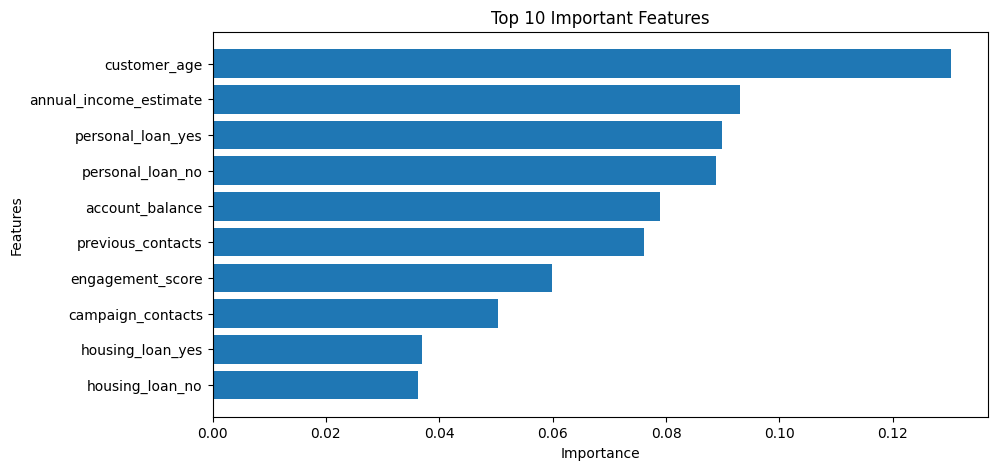

In [203]:
top_10_features = feature_importance.head(10)
plt.figure(figsize=(10, 5))
plt.barh(top_10_features['Feature'], top_10_features['Importance'])
plt.xlabel('Importance')
plt.ylabel('Features')
plt.title('Top 10 Important Features')
plt.gca().invert_yaxis()
plt.show()

Feature importance helps identify which features the Random Forest model relied on most when making predictions. but  feature importance does not prove that a feature causes a customer to subscribe.

In [204]:
selected_model = random_forest_model

In [205]:
sample_customers = x_test.head(5)

In [206]:
sample_predictions = selected_model.predict(sample_customers)
sample_probabilities = selected_model.predict_proba(sample_customers)
yes_index = list(selected_model.classes_).index('yes')
yes_probabilities = sample_probabilities[:, yes_index]

In [207]:
prediction_results = pd.DataFrame({
    'Actual': y_test.loc[sample_customers.index],
    'Predicted': sample_predictions,
    'Probability of Yes': yes_probabilities})
prediction_results

,Actual,Predicted,Probability of Yes
269,no,no,0.16
70,yes,yes,0.85
376,yes,no,0.22
543,yes,yes,0.78
429,no,no,0.01


we did Two models Logistic Regression and Random Forest. Random Forest was recommended because it had higher recall (60%), helping identify more potential subscribers.both performed similarly. this will help to find who all would likely to subscribe to a term deposit after a marketing campaign.